# Solutions

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Polynomial fitting with SVD

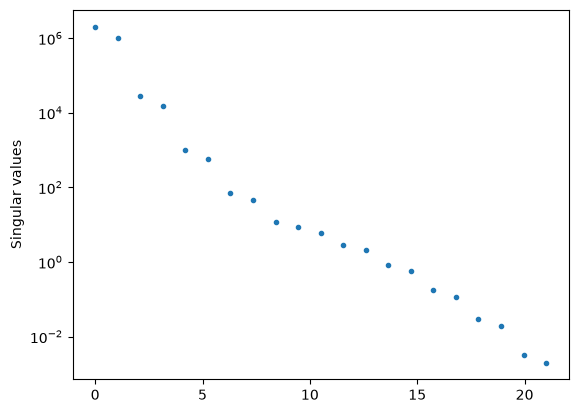

Range of singular values = 1.02088e+09
np.linalg.cond gives 1.02088e+09
Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error
x^0     -0.813025     -0.813025   3.79272e-11
x^1     -0.815332     -0.815332  -8.41441e-11
x^2      0.384035      0.384035   1.77003e-09
x^3      0.130716      0.130716   -6.7687e-09
x^4      -0.58931      -0.58931    1.0481e-08
x^5    -0.0383475    -0.0383475  -1.25009e-07
x^6     0.0735364     0.0735364   2.79738e-07
x^7     0.0343743     0.0343743   -2.3169e-07
x^8      0.360867      0.360867  -9.35984e-08
x^9      -0.72319      -0.72319  -9.39705e-09
x^10       0.35537       0.35537   1.00425e-07
x^11     -0.996129     -0.996129    9.3258e-11
x^12     -0.171379     -0.171379   1.08268e-07
x^13      0.545053      0.545053   1.64274e-09
x^14      0.587834      0.587834   1.00569e-08
x^15     -0.691228     -0.691228   2.80628e-10
x^16      0.859809      0.859809  -1.73945e-09
x^17      0.262318      0.262318   3.19114e-10
x^18      0.926803     

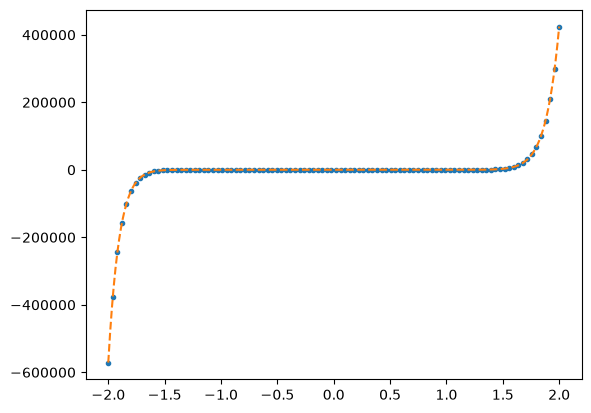

In [2]:
# first generate some data from a random polynomial

k = 20 # order of polynomial
n = 100  # number of data points
sigma = 0 # noise
useSVD = True

x = np.linspace(-2,2,n)
# generate random coefficients, each between -1 and 1
a0 = -1.0 + 2*np.random.rand(k+1)
# generate the polynomial and add some noise
poly = np.polynomial.Polynomial(a0)
y = poly(x) + np.random.normal(scale=sigma, size=n)

# Compute the design matrix
# A_{ij} = f_j(x_i)
A = np.zeros((n, k+1))
for kk in range(k+1):
    A[:, kk] = x**kk
# We could also use:
# A = np.vander(x, N=k+1, increasing=True)

# SVD
U, Sdiag, VT = np.linalg.svd(A,full_matrices=False)

# plot the singular values
plt.clf()
plt.plot(np.linspace(0,len(Sdiag),len(Sdiag)),Sdiag,'.')
plt.yscale('log')
plt.ylabel(r'Singular values')
plt.show()
    
print("Range of singular values = %g" % (max(abs(Sdiag))/min(abs(Sdiag))))
print("np.linalg.cond gives %g" % (np.linalg.cond(A)))

# Now do the linear algebra part
if useSVD:
    a = VT.T @ np.diag(1/Sdiag) @ U.T @ y
else:
    rhs = np.transpose(A)@y
    lhs = np.transpose(A)@A
    a = np.linalg.inv(lhs)@rhs

print("Polynomial order, Polynomial coeffs, Fitted coeffs, Fractional error")
for i in range(k+1):
    print("x^%d %13g %13g %13g" % (i, a0[i], a[i], (a[i]-a0[i])/a0[i]))

# Plot the fitted polynomial on top of the original
plt.figure()
plt.plot(x,y,'.')
xx = np.linspace(-2,2,1000)
poly = np.polynomial.Polynomial(a)
yy = poly(xx)
plt.plot(xx,yy,'--')

if sigma>0.0:
    chi2 = np.mean((y-poly(x))**2)/sigma**2
else:
    chi2 = np.mean((y-poly(x))**2)
print('reduced chi2 = %g' % (chi2,))

plt.show()

## Orthogonal polynomials

In [3]:
# Visualize matrices as a color map
def plot_matrices(A,titles=[]):
    n = len(A)
    if titles==[]:
        titles = [""]*n
    if n>4:
        nx = 4
    else:
        nx = n
    for j in range(int(np.floor(n/4))+1):        
        plt.clf()
        plt.figure(figsize=(nx*4,4))
        jmax = 4*(j+1)
        if jmax > n:
            jmax = n
        for i,AA in enumerate(A[4*j:jmax]):
            plt.subplot(1, nx, i+1)
            plt.imshow(AA)
            plt.colorbar()
            plt.title(titles[4*j + i])
        plt.show()

In [4]:
# first generate some data from a random polynomial
k = 20  # order of polynomial
n = 100   # number of data points

kfit = 20  # number of basis functions for the fit

x = np.linspace(-2,2,n)
a0 = -1.0 + 2*np.random.rand(k+1)
poly = np.polynomial.Polynomial(a0)
y = poly(x) + np.random.normal(scale=0.0, size=n)

# OR try a more complicated function
#y = np.exp(np.sin(x**3)) + np.tanh(x)**3

In [5]:
def do_fit(A, y, use_svd = True):
    
    if use_svd:
        U, Sdiag, VT = np.linalg.svd(A,0)
        a = VT.T @ np.diag(1/Sdiag) @ U.T @ y
    else:
        rhs = np.transpose(A)@y
        lhs = np.transpose(A)@A
        a = np.linalg.inv(lhs)@rhs

    return a

<Figure size 640x480 with 0 Axes>

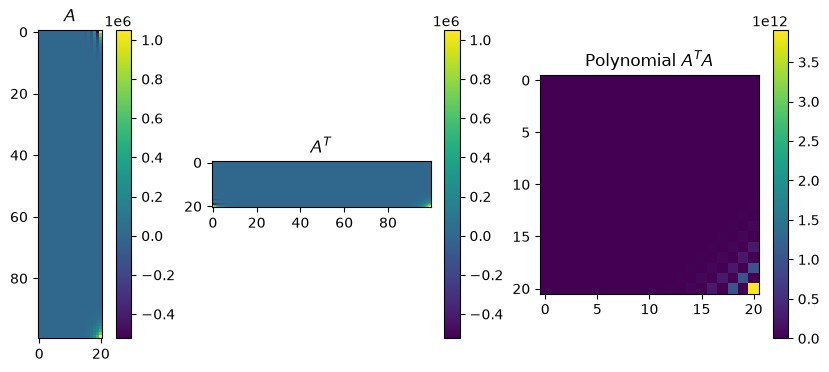

Condition number = 1.02088e+09


<Figure size 640x480 with 0 Axes>

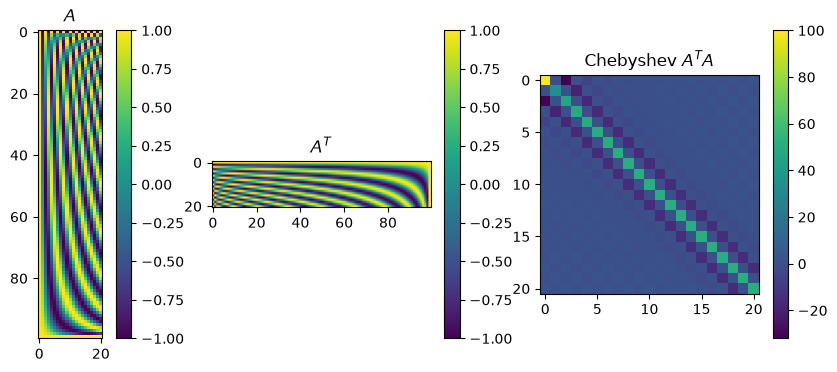

Condition number = 3.1319
Chebyshev coefficients:
a0 -152401
a1 52000.9
a2 -277466
a3 43272.4
a4 -208945
a5 29787.4
a6 -129464
a7 16758.3
a8 -65353.8
a9 7562.1
a10 -26456.1
a11 2663.13
a12 -8381.92
a13 702.95
a14 -2001.31
a15 130.393
a16 -338.439
a17 15.1056
a18 -36.1074
a19 0.819233
a20 -1.82623
mean square deviation = 5.01559e-20


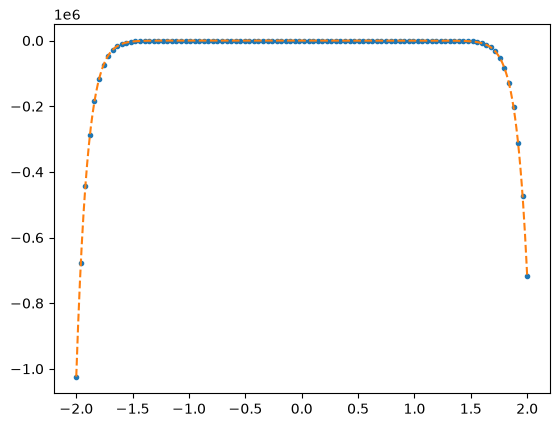

In [6]:
# As a comparison, compute the design matrix as if we were using regular polynomials
A = np.vander(x, N=kfit+1, increasing=True)
plot_matrices([A,A.T,A.T@A], titles=[r"$A$",r"$A^T$",r"Polynomial $A^TA$"])
print("Condition number = %g" % (np.linalg.cond(A)))

# Fit with Chebyshev polynomials
A = np.polynomial.chebyshev.chebvander(x/2,kfit)
plot_matrices([A,A.T,A.T@A], titles=[r"$A$",r"$A^T$",r"Chebyshev $A^TA$"])
print("Condition number = %g" % (np.linalg.cond(A)))

a_cheb = do_fit(A, y)
      
print("Chebyshev coefficients:")
for i in range(len(a_cheb)):
    print("a%d %g" % (i, a_cheb[i]))

plt.figure()
plt.plot(x,y,'.')

xx = np.linspace(-2,2,1000)
poly_cheb = np.polynomial.Chebyshev(a_cheb)
yy = poly_cheb(xx/2)
plt.plot(xx,yy,'--')

chi2 = np.mean((y-poly_cheb(x/2))**2)
print('mean square deviation = %g' % (chi2,))
plt.show()

<Figure size 640x480 with 0 Axes>

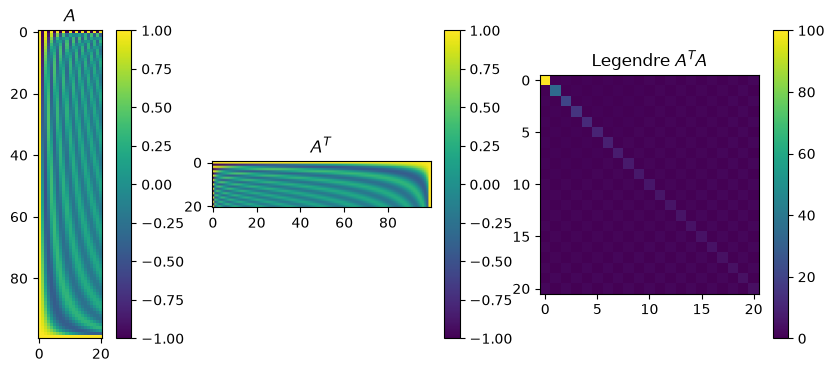

Condition number = 6.42377
Legendre coefficients:
a0 -40908.9
a1 20287.2
a2 -178221
a3 37900.7
a4 -232062
a5 39611.5
a6 -200141
a7 29448.8
a8 -127665
a9 16344.7
a10 -61835.1
a11 6775.61
a12 -22635.3
a13 2043.64
a14 -6094.99
a15 423.991
a16 -1141.94
a17 54.0548
a18 -133.162
a19 3.18556
a20 -7.28332
mean square deviation = 2.01841e-18


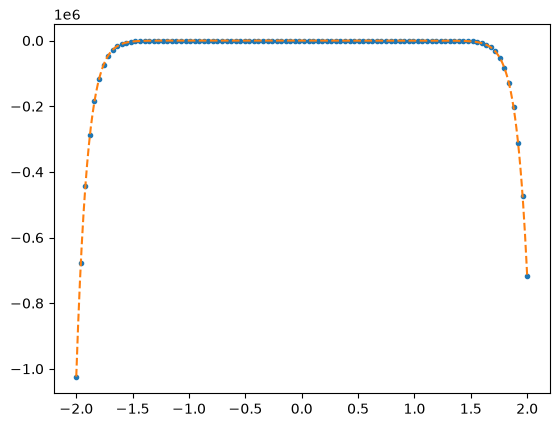

In [7]:
# Fit with Legendre polynomials
A = np.polynomial.legendre.legvander(x/2,kfit)

plot_matrices([A,A.T,A.T@A], titles=[r"$A$",r"$A^T$",r"Legendre $A^TA$"])
print("Condition number = %g" % (np.linalg.cond(A)))

a_leg = do_fit(A, y)
      
print("Legendre coefficients:")
for i in range(len(a_leg)):
    print("a%d %g" % (i, a_leg[i]))

plt.figure()
plt.plot(x,y,'.')

xx = np.linspace(-2,2,1000)
poly_leg = np.polynomial.Legendre(a_leg)
yy = poly_leg(xx/2)
plt.plot(xx,yy,'--')

chi2 = np.mean((y-poly_leg(x/2))**2)
print('mean square deviation = %g' % (chi2,))
plt.show()